# Issue #286 — joint base-ticket and selective-protection learning

This notebook is the decision surface for the bounded joint action
`(N, selector, outcome mode, generator, K, protection policy)`. The independent
unit is a Beijing issue. All economics are pre-tax, use actual CNY2 unique-ticket
stake, and apply 0.65 once to a winning complete N-fold. 2024+ remains sealed.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
ART = ROOT / 'docs/research/artifacts/issue-286'
RESULTS = ROOT / 'results/issue-286'
summary = pd.read_csv(ART / 'joint_policy_comparison_summary.csv')
annual = pd.read_csv(ART / 'joint_policy_annual.csv')
protection = pd.read_csv(ART / 'joint_policy_protection_attribution.csv')
actions = pd.read_csv(ART / 'joint_policy_action_distribution.csv')
candidate_universe = pd.read_csv(ART / 'candidate_universe_summary.csv')
manifest = json.loads((RESULTS / 'label_free_manifest_receipt.json').read_text())
settlement = json.loads((RESULTS / 'settlement_receipt.json').read_text())
oof = json.loads((RESULTS / 'joint_oof_receipt.json').read_text())
assert manifest['settlement_columns_opened'] == []
assert settlement['sealed_years_opened'] == []
{'manifest': manifest['rows'], 'settlement': settlement['settlement_rows'], 'oof': oof}

{'manifest': {'base': 1188800, 'candidate': 12801489, 'continuation': 1188800},
 'settlement': {'base': 1188800,
  'candidate': 12801489,
  'continuation': 1188800},
 'oof': {'contract': 'BJ-UNIFIED-JOINT-PROTECTION-001/oof-v1',
  'oof_years': [2019, 2020, 2021, 2022, 2023],
  'models': ['ACTION_RIDGE', 'DATA_HGB'],
  'protection_shares': [0.0, 0.1, 0.25, 0.5, 1.0],
  'candidate_negative_sample_per_issue_action': 24,
  'candidate_sample_rows': 717779,
  'issue_weighting': 'EACH_TRAINING_ISSUE_SUMS_TO_ONE',
  'maximum_base_issue_weight_error': 0.0,
  'maximum_candidate_issue_weight_error': 0.0,
  'formal_baseline': 'SALL_OMARKET_N7_TOP_VALUE_K8',
  'cash_action': True,
  'settlement_fields_in_inputs': [],
  'input_sha256': {'settlement_labels': {'base': '18774f7e1fb84311dfff5e616ecc5d6d15fdaf52c4f2d82450b17343432a7c06',
    'candidate': '87c07c0005c3d8def9c9d8e43a694f7159f901a70375e230fa5558c2a48b64e1',
    'continuation': '2a06bbf9c3abccb45663522f4e1fc24bfaf51c780ad555bd771b06f2ae6695e

## Matched capital comparison

In [2]:
summary.loc[
    summary.model.eq('DATA_HGB'),
    ['policy','turnover_cny','pnl_cny','roi_pct','ending_capital_cny',
     'ex_largest_pnl_cny','bootstrap_roi_p025','bootstrap_roi_p975',
     'max_drawdown_pct','worst_rolling_10_pnl_cny']
]

,policy,turnover_cny,pnl_cny,roi_pct,ending_capital_cny,ex_largest_pnl_cny,bootstrap_roi_p025,bootstrap_roi_p975,max_drawdown_pct,worst_rolling_10_pnl_cny
7,LEARNED_JOINT,36126.0,9975.984830,27.614419,109975.984830,-24279.300323,-91.708107,254.536138,13.819255,-2560.0
8,SELECTED_BASE_NO_PROTECTION,20320.0,17186.634728,84.579895,117186.634728,-17196.650425,-97.628356,466.389884,10.033106,-1280.0
9,SAME_BUDGET_RANDOM,36126.0,2517.361604,6.968282,102517.361604,-31737.923550,-96.949476,223.411058,18.648175,-2560.0
10,SAME_BUDGET_CONTINUATION,36126.0,3555.380646,9.841612,103555.380646,-30699.904507,-97.047785,228.671084,17.824463,-2560.0
11,SAME_BUDGET_ADVERSE_HEURISTIC,36126.0,6692.526840,18.525513,106692.526840,-27562.758313,-94.035826,241.187306,18.050143,-2560.0
12,UNATTAINABLE_ORACLE_UPPER_BOUND,36126.0,93157.841562,257.869240,193157.841562,58902.556409,63.890547,523.951527,2.703701,-2560.0
13,FORMAL_N7_K8_MARKET_TOP,4304.0,4738.610145,110.097819,104738.610145,2980.063026,1.515209,241.499939,1.273065,-160.0


The positive HGB totals are not evidence of stable Edge. Removing
one largest issue makes both the selected base and learned joint paths negative.
The issue bootstrap crosses zero widely. The formal N7/K8 row is a required
reference selected using 2014–2022, so only its 2023 result is a truly frozen
holdout observation.

In [3]:
annual.loc[
    annual.model.eq('DATA_HGB') & annual.policy.isin([
        'LEARNED_JOINT','SELECTED_BASE_NO_PROTECTION','FORMAL_N7_K8_MARKET_TOP'
    ])
].pivot(index='issue_year', columns='policy', values=['pnl_cny','roi_pct'])

pnl_cny                                            \
policy     FORMAL_N7_K8_MARKET_TOP LEARNED_JOINT SELECTED_BASE_NO_PROTECTION   
issue_year                                                                     
2019                   1331.891953  22601.285153                28335.285153   
2020                   2300.153740  -8342.000000                -4288.000000   
2021                   2329.148891  -3567.283711                -1695.283711   
2022                   -942.271334   -865.603159                -2381.366714   
2023                   -280.313106    149.586548                -2784.000000   

                           roi_pct                                            
policy     FORMAL_N7_K8_MARKET_TOP LEARNED_JOINT SELECTED_BASE_NO_PROTECTION  
issue_year                                                                    
2019                    157.062730    189.767298                  458.796716  
2020                    378.314760   -100.000000                 -100.000000  
2021                    231.066358    -58.827238                  -40.440928  
2022                    -94.987030    -16.840528                  -82.686344  
2023                    -33.055791      3.203138                 -100.000000

## Did selective protection add value?

In [4]:
candidate_universe

,issue_year,candidates,valid_candidates,winning_candidates,stake_cny,gross_cny,pnl_cny,winner_rate
0,2014,2807403,2807403,1044,5614806.0,5.223711e+06,-391095.019474,0.000372
1,2015,1135841,1122775,410,2245550.0,1.721288e+06,-524262.320824,0.000365
2,2016,1095122,1075084,407,2150168.0,2.144114e+06,-6053.951652,0.000379
3,2017,990726,847210,339,1694420.0,1.807302e+06,112882.177090,0.000400
4,2018,1217841,1115013,398,2230026.0,1.982655e+06,-247370.610650,0.000357
5,2019,1097229,1094586,404,2189172.0,1.775906e+06,-413266.253214,0.000369
6,2020,769392,769392,259,1538784.0,1.113496e+06,-425287.646912,0.000337
7,2021,1307159,1304481,459,2608962.0,2.162698e+06,-446264.065364,0.000352
8,2022,1286748,1286748,392,2573496.0,1.641696e+06,-931800.038374,0.000305
9,2023,1094028,1094028,387,2188056.0,1.956839e+06,-231216.849071,0.000354


In [5]:
protection

,model,issue_year,issues,funded_issues,protection_tickets,predicted_protection_pnl_cny,actual_protection_pnl_cny,base_pnl_cny,joint_pnl_cny
0,ACTION_RIDGE,2019,53,53,0,0.000000,0.000000,-1696.000000,-1696.000000
1,ACTION_RIDGE,2020,38,38,0,0.000000,0.000000,-1216.000000,-1216.000000
2,ACTION_RIDGE,2021,63,63,0,0.000000,0.000000,-2016.000000,-2016.000000
3,ACTION_RIDGE,2022,62,62,0,0.000000,0.000000,-1984.000000,-1984.000000
4,ACTION_RIDGE,2023,53,53,0,0.000000,0.000000,-1696.000000,-1696.000000
5,DATA_HGB,2019,53,52,2867,3868.903013,-5734.000000,28335.285153,22601.285153
6,DATA_HGB,2020,38,38,2027,3666.395455,-4054.000000,-4288.000000,-8342.000000
7,DATA_HGB,2021,63,53,936,221.936464,-1872.000000,-1695.283711,-3567.283711
8,DATA_HGB,2022,62,33,1130,679.061846,1515.763555,-2381.366714,-865.603159
9,DATA_HGB,2023,53,30,943,406.300828,2933.586548,-2784.000000,149.586548


In [6]:
hgb = protection.loc[protection.model.eq('DATA_HGB')]
stake = 2 * hgb.protection_tickets.sum()
pd.Series({
    'protection_tickets': int(hgb.protection_tickets.sum()),
    'protection_stake_cny': stake,
    'predicted_incremental_pnl_cny': hgb.predicted_protection_pnl_cny.sum(),
    'actual_incremental_pnl_cny': hgb.actual_protection_pnl_cny.sum(),
    'incremental_roi_pct': hgb.actual_protection_pnl_cny.sum() / stake * 100,
})

protection_tickets                7903.000000
protection_stake_cny             15806.000000
predicted_incremental_pnl_cny     8842.597606
actual_incremental_pnl_cny       -7210.649897
incremental_roi_pct                -45.619701
dtype: float64

The learned ranker loses less than equal-budget adverse, continuation,
and random controls, but loses CNY7,210.65 relative to choosing no protection.
This preserves a ranking clue while rejecting the funded protection action.

## Joint action distribution and sparsity

In [7]:
actions.loc[actions.model.eq('DATA_HGB')].sort_values(
    ['issues','protection_tickets'], ascending=False
).head(20)

,model,n,k,selector,outcome_mode,generator,protection_share,issues,protection_tickets
3,DATA_HGB,9,64,UNIFORM,DIVERGENCE_VALUE,WEIGHTED_WR,1.0,31,1975
4,DATA_HGB,9,64,UNIFORM,MARKET_PROBABILITY,WEIGHTED_WR,1.0,17,1011
5,DATA_HGB,9,64,DIVERGENCE_WEIGHTED,MARKET_PROBABILITY,WEIGHTED_WR,1.0,13,832
6,DATA_HGB,8,64,UNIFORM,MARKET_PROBABILITY,TOP_VALUE,1.0,6,384
7,DATA_HGB,8,64,UNIFORM,MARKET_PROBABILITY,WEIGHTED_WR,1.0,6,384
9,DATA_HGB,9,64,DIVERGENCE_WEIGHTED,DIVERGENCE_VALUE,WEIGHTED_WR,1.0,6,384
10,DATA_HGB,9,64,UNIFORM,MARKET_PROBABILITY,TOP_VALUE,1.0,6,358
8,DATA_HGB,9,16,UNIFORM,MARKET_PROBABILITY,WEIGHTED_WR,1.0,6,94
12,DATA_HGB,8,64,UNIFORM,DIVERGENCE_VALUE,WEIGHTED_WR,1.0,5,320
11,DATA_HGB,7,16,UNIFORM,DIVERGENCE_VALUE,TOP_VALUE,0.0,5,0


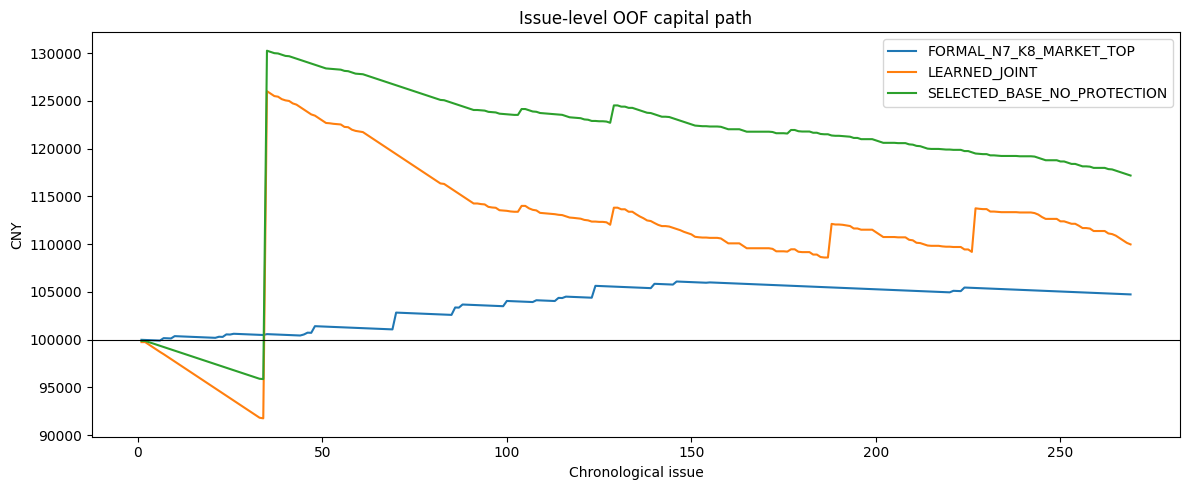

In [8]:
paths = pd.read_csv(ART / 'joint_policy_capital_paths.csv')
focus = paths.loc[
    paths.model.eq('DATA_HGB') & paths.policy.isin([
        'LEARNED_JOINT','SELECTED_BASE_NO_PROTECTION','FORMAL_N7_K8_MARKET_TOP'
    ])
]
fig, ax = plt.subplots(figsize=(12,5))
for policy, group in focus.groupby('policy', sort=True):
    ax.plot(range(1, len(group)+1), group.capital_cny, label=policy)
ax.axhline(100_000, color='black', linewidth=.8)
ax.set(title='Issue-level OOF capital path', xlabel='Chronological issue', ylabel='CNY')
ax.legend(); plt.tight_layout()

## Decision

No learned protection policy is promoted. Data-HGB often selects 100% protection,
which reproduces the blanket behavior the contract sought to avoid. The base
selector's positive total is one-issue dominated. Preserve `NO_PROTECTION`, the
candidate score, and the complete label-free interface; next work should improve
base-action value and tail-risk calibration before reopening protection.